<a href="https://colab.research.google.com/github/nhentze1/Minimum-Wages-and-Business-Models-Company-Owned-vs.-Franchise-Restaurants/blob/main/minwageDiD_NEW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Minimum Wages and Restaurant Business Models: Company-Owned vs. Franchise Stores

This notebook replicates selected analyses from Card and Krueger (1994) and extends them to examine whether the minimum-wage increase had different effects on employment, meal prices, and daily opening hours at company-owned and franchised restaurants.



## Loading Libraries and Data



In [ ]:
%pip install pandas numpy matplotlib seaborn openpyxl statsmodels -q
!pip install pyfixest -q
from pathlib import Path
import pandas as pd
import numpy as np
import pyfixest as pf
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import display, Markdown
from scipy.stats import f as f_distribution

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)

url_to_excel = "https://raw.githubusercontent.com/nhentze1/Minimum-Wages-and-Business-Models-Company-Owned-vs.-Franchise-Restaurants/main/CardKrueger_1994_Fastfood.xlsx"
local_file = Path("CardKrueger_1994_Fastfood.xlsx")
data_source = local_file if local_file.exists() else url_to_excel
excel_file = pd.ExcelFile(data_source)
df = pd.read_excel(excel_file, sheet_name="Daten")
display(df)

,sheet,chain,co_owned,state,southj,centralj,northj,pa1,pa2,shore,...,firstin2,special2,meals2,open2r,hrsopen2,psoda2,pfry2,pentree2,nregs2,nregs112
0,46,1,0,0,0,0,0,1,0,0,...,0.08,1.0,2.0,6.5,16.5,1.03,NaN,0.94,4.0,4.0
1,49,2,0,0,0,0,0,1,0,0,...,0.05,0.0,2.0,10.0,13.0,1.01,0.89,2.35,4.0,4.0
2,506,2,1,0,0,0,0,1,0,0,...,0.25,NaN,1.0,11.0,11.0,0.95,0.74,2.33,4.0,3.0
3,56,4,1,0,0,0,0,1,0,0,...,0.15,0.0,2.0,10.0,12.0,0.92,0.79,0.87,2.0,2.0
4,61,4,1,0,0,0,0,1,0,0,...,0.15,0.0,2.0,10.0,12.0,1.01,0.84,0.95,2.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
405,423,2,1,1,0,0,1,0,0,0,...,0.50,0.0,1.0,11.0,11.0,1.05,0.84,2.32,3.0,2.0
406,424,2,1,1,0,0,1,0,0,0,...,0.50,0.0,1.0,11.0,14.0,1.05,0.94,2.32,5.0,3.0
407,426,3,1,1,0,0,1,0,0,0,...,0.25,1.0,2.0,6.0,18.0,1.11,1.05,1.05,6.0,5.0
408,427,4,0,1,0,0,1,0,0,0,...,NaN,1.0,2.0,10.5,12.5,1.11,1.09,2.07,2.0,2.0


## Variable Guide



In [ ]:
variable_definitions = pd.DataFrame([
    # Identifiers and group indicators
    ("sheet", "Worksheet/record identifier in this dataset"),
    ("state", "1 = New Jersey; 0 = Pennsylvania"),
    ("co_owned", "1 = company-owned; 0 = franchise"),
    ("franchise", "1 = franchise; 0 = company-owned; derived as 1 − co_owned"),
    ("chain", "1 = Burger King; 2 = KFC; 3 = Roy Rogers; 4 = Wendy's"),

    # Employment and wages
    ("empft / emppt / nmgrs", "Baseline full-time workers / part-time workers / managers"),
    ("empft2 / emppt2 / nmgrs2", "Follow-up full-time workers / part-time workers / managers"),
    ("fte_before / fte_after", "Full-time-equivalent employment before / after: full-time workers + managers + 0.5 × part-time workers"),
    ("change_fte", "Follow-up FTE employment minus baseline FTE employment"),
    ("proportional_change", "Change in FTE employment divided by average FTE employment across the two waves; closed stores are coded as −1"),
    ("log_change_percent", "100 × the change in log FTE employment; calculated only when FTE employment is positive in both waves"),
    ("wage_st / wage_st2", "Baseline / follow-up starting hourly wage (USD)"),
    ("gap", "Proportional baseline-wage increase needed to reach $5.05; set to 0 in Pennsylvania and for NJ stores already paying at least $5.05"),

    # Prices and opening hours
    ("psoda / pfry / pentree", "Baseline tax-inclusive prices (USD) for a medium soda / small fries / main entrée"),
    ("psoda2 / pfry2 / pentree2", "Follow-up tax-inclusive prices (USD) for a medium soda / small fries / main entrée"),
    ("meal_price_before / meal_price_after", "Baseline / follow-up full-meal price: soda + fries + entrée"),
    ("change_price", "Follow-up full-meal price minus baseline full-meal price"),
    ("hrsopen / hrsopen2", "Daily opening hours at baseline / follow-up"),
    ("change_hours", "Follow-up daily opening hours minus baseline daily opening hours"),

    # Sample and survey details
    ("status2", "Follow-up status: 0 = refused; 1 = interviewed; 2 = renovation; 3 = permanently closed; 4 = road construction; 5 = fire"),
    ("date2", "Date of the follow-up interview"),
    ("ncalls", "Number of callbacks required for the baseline interview"),
], columns=["Variable", "Definition"])

display(variable_definitions)

,Variable,Definition
0,sheet,Worksheet/record identifier in this dataset
1,state,1 = New Jersey; 0 = Pennsylvania
2,co_owned,1 = company-owned; 0 = franchise
3,franchise,1 = franchise; 0 = company-owned; derived as 1 − co_owned
4,chain,1 = Burger King; 2 = KFC; 3 = Roy Rogers; 4 = Wendy's
5,empft / emppt / nmgrs,Baseline full-time workers / part-time workers / managers
6,empft2 / emppt2 / nmgrs2,Follow-up full-time workers / part-time workers / managers
7,fte_before / fte_after,Full-time-equivalent employment before / after: full-time workers + managers + 0.5 × part-time workers
8,change_fte,Follow-up FTE employment minus baseline FTE employment
9,proportional_change,Change in FTE employment divided by average FTE employment across the two waves; closed stores are coded as −1


# Plotting and Understanding the Data



On April 1, 1992, New Jersey increased its minimum wage from USD 4.25 to USD 5.05 per hour; Pennsylvania retained USD 4.25. The first survey was in February/March and the second in November/December 1992.

- **Employment:** full-time workers + managers + 0.5 x part-time workers, in full-time equivalents (FTE). A missing component makes the total missing. Permanently closed restaurants have zero follow-up employment; temporary closures and refusals are not automatically set to zero.
- **Prices:** the sum of a medium soda, small fries, and main entree, in nominal tax-inclusive USD. All three components must be observed. This is a fixed item basket, not a transaction-weighted price index.
- **Operations:** reported daily opening hours. Main price and hours estimates require an interviewed restaurant at follow-up; they describe the observed operating sample rather than all original restaurants.

Includes their Table 1: But the Wave 1 frame and refusal records are not present in this dataset, hence those counts and response rates cannot be calculated from df

In [ ]:
analysis = df.copy()

# Converting the variables used below to numeric values
columns_to_convert = [
    "sheet", "chain", "state", "co_owned", "status2",
    "empft", "nmgrs", "emppt", "empft2", "nmgrs2", "emppt2",
    "psoda", "pfry", "pentree", "psoda2", "pfry2", "pentree2",
    "hrsopen", "hrsopen2", "wage_st", "wage_st2",
]
analysis[columns_to_convert] = analysis[columns_to_convert].apply(
    pd.to_numeric, errors="coerce"
)

# Adding labels for states, ownership, chains, and Wave 2 status
analysis["state_name"] = analysis["state"].map({
    0: "Pennsylvania",
    1: "New Jersey",
})

analysis["franchise"] = 1 - analysis["co_owned"]
analysis["ownership"] = analysis["franchise"].map({
    0: "Company-owned",
    1: "Franchise",
})

analysis["chain_name"] = analysis["chain"].map({
    1: "Burger King",
    2: "KFC",
    3: "Roy Rogers",
    4: "Wendy's",
})

analysis["follow_up_status"] = analysis["status2"].map({
    0: "Refused interview",
    1: "Interviewed",
    2: "Closed for renovation",
    3: "Permanently closed",
    4: "Closed for road construction",
    5: "Closed after shopping-center fire",
})


# Creating the outcome variables for Wave 1 (before) and Wave 2 (after)
for wave, suffix in [("before", ""), ("after", "2")]:
    # Full-time-equivalent employment: full-time workers + managers + half of part-time workers
    analysis[f"employment_{wave}"] = (
        analysis[f"empft{suffix}"]
        + analysis[f"nmgrs{suffix}"]
        + 0.5 * analysis[f"emppt{suffix}"])

    # Fixed meal basket: medium soda + small fries + main entree
    analysis[f"meal_price_{wave}"] = (
        analysis[f"psoda{suffix}"]
        + analysis[f"pfry{suffix}"]
        + analysis[f"pentree{suffix}"])

    # Reported daily opening hours
    analysis[f"hours_{wave}"] = analysis[f"hrsopen{suffix}"]


# Permanently closed restaurants are assigned zero follow-up employment
analysis.loc[analysis["status2"].eq(3), "employment_after"] = 0

# Other non-interviewed stores have no observed follow-up employment
analysis.loc[analysis["status2"].ne(1) & analysis["status2"].ne(3), "employment_after"] = np.nan

# Follow-up prices and hours are available only for interviewed stores
analysis.loc[analysis["status2"].ne(1), ["meal_price_after", "hours_after"]] = np.nan


# Keep restaurants observed in both waves for each outcome
outcomes = {
    "employment": "Employment (FTE)",
    "meal_price": "Meal basket price (USD)",
    "hours": "Daily opening hours",
}

# Creates a separate before-and-after sample for each outcome
samples = {}

for outcome in outcomes:
    before = f"{outcome}_before"
    after = f"{outcome}_after"

    sample = analysis.dropna(subset=[before, after]).copy()
    sample["change"] = sample[after] - sample[before]
    samples[outcome] = sample


# Build Table 1 from counts in the dataset
# The dataset includes Wave 1 interviewees, but not the original full frame
# or the stores that refused the Wave 1 interview
state_order = [1, 0]  # New Jersey, then Pennsylvania
state_labels = ["New Jersey", "Pennsylvania"]

def count_by_state(condition):
    """Count records meeting a condition for all stores and each state"""
    counts = []
    for state_code in [None] + state_order: #runs 3 times, once for all and then for NJ & PA
        if state_code is None:
            counts.append(int(condition.sum())) #counts all true values
        else:
            counts.append(int((condition & analysis["state"].eq(state_code)).sum())) #Otherwise, it counts rows where both the condition is true and the row is from that state
    return counts

def stores_by_state():
    """Count the Wave 1 interview records in the dataset"""
    return [
        len(analysis),
        int(analysis["state"].eq(1).sum()),
        int(analysis["state"].eq(0).sum()),
    ]

table1_rows = []

# The Wave 1 frame and refusal records are not present in this dataset,
# so those counts and response rates cannot be calculated from df
table1_rows.extend([
    ("Wave 1: Feb 15–Mar 4, 1992", "Stores in sample frame",
     "Not in dataset", "Not in dataset", "Not in dataset"),
    ("Wave 1: Feb 15–Mar 4, 1992", "Refusals",
     "Not in dataset", "Not in dataset", "Not in dataset"),
    ("Wave 1: Feb 15–Mar 4, 1992", "Interviewed",
     *stores_by_state()), #unpacks the list and returns tuple
    ("Wave 1: Feb 15–Mar 4, 1992", "Response rate (%)",
     "Cannot calculate", "Cannot calculate", "Cannot calculate"),
])

# The Wave 2 frame is the group interviewed in Wave 1, represented by rows
# in this dataset, calculating Wave 2 outcomes from the status variable
table1_rows.append((
    "Wave 2: Nov 5–Dec 31, 1992",
    "Stores in sample frame",
    *stores_by_state(),
))

wave2_status_rows = [
    ("Permanently closed", analysis["status2"].eq(3)),
    ("Under renovation", analysis["status2"].eq(2)),
    ("Temporarily closed", analysis["status2"].isin([4, 5])), #either 4 or 5
    ("Refusals", analysis["status2"].eq(0)),
    ("Interviewed", analysis["status2"].eq(1)),
]

for label, condition in wave2_status_rows:
    table1_rows.append((
        "Wave 2: Nov 5–Dec 31, 1992",
        label,
        *count_by_state(condition),
    ))

table1 = pd.DataFrame(
    table1_rows,
    columns=[
        "Survey wave",
        "Measure",
        "All",
        "New Jersey",
        "Pennsylvania",
    ], ).set_index(["Survey wave", "Measure"])

print("Table 1: Sample design and response rates available in the dataset")
display(table1)


# Showing the employment means by state and wave
print("Average employment (FTE) by state and survey wave:")
employment_means = analysis.groupby("state_name")[
    ["employment_before", "employment_after"]
].mean()
display(employment_means.round(2))


# Showing the number of restaurants by state and ownership
print("Restaurants by state and ownership:")
display(pd.crosstab(analysis["state_name"], analysis["ownership"])) #cross-tabulation


# Showing follow-up status by state
print("Wave 2 status by state:")
display(pd.crosstab(analysis["follow_up_status"], analysis["state_name"]))


# Showing the paired sample sizes used for each outcome
print("Paired sample sizes by state and ownership:")
# Count paired restaurants in each state and ownership group for each outcome, then place the counts side by side
paired_count_columns = {}

for outcome, sample in samples.items():
    label = outcomes[outcome]

    group_counts = sample.groupby(["state_name", "ownership"]).size()

    paired_count_columns[label] = group_counts

paired_counts = pd.concat(paired_count_columns, axis=1)

display(paired_counts)


# Showing the number of restaurants by chain, state, and ownership
print("Restaurants by chain, state, and ownership:")
display(
    pd.crosstab(
        [analysis["chain_name"], analysis["state_name"]],
        analysis["ownership"],
    )
)

Table 1: Sample design and response rates available in the dataset


All  \
Survey wave                Measure                                    
Wave 1: Feb 15–Mar 4, 1992 Stores in sample frame    Not in dataset   
                           Refusals                  Not in dataset   
                           Interviewed                          410   
                           Response rate (%)       Cannot calculate   
Wave 2: Nov 5–Dec 31, 1992 Stores in sample frame               410   
                           Permanently closed                     6   
                           Under renovation                       2   
                           Temporarily closed                     2   
                           Refusals                               1   
                           Interviewed                          399   

                                                         New Jersey  \
Survey wave                Measure                                    
Wave 1: Feb 15–Mar 4, 1992 Stores in sample frame    Not in dataset   
                           Refusals                  Not in dataset   
                           Interviewed                          331   
                           Response rate (%)       Cannot calculate   
Wave 2: Nov 5–Dec 31, 1992 Stores in sample frame               331   
                           Permanently closed                     5   
                           Under renovation                       2   
                           Temporarily closed                     2   
                           Refusals                               1   
                           Interviewed                          321   

                                                       Pennsylvania  
Survey wave                Measure                                   
Wave 1: Feb 15–Mar 4, 1992 Stores in sample frame    Not in dataset  
                           Refusals                  Not in dataset  
                           Interviewed                           79  
                           Response rate (%)       Cannot calculate  
Wave 2: Nov 5–Dec 31, 1992 Stores in sample frame                79  
                           Permanently closed                     1  
                           Under renovation                       0  
                           Temporarily closed                     0  
                           Refusals                               0  
                           Interviewed                           78

Average employment (FTE) by state and survey wave:


,employment_before,employment_after
state_name,,
New Jersey,20.44,21.03
Pennsylvania,23.33,21.17


Restaurants by state and ownership:


ownership,Company-owned,Franchise
state_name,,
New Jersey,113,218
Pennsylvania,28,51


... (2 outputs left out)

Paired sample sizes by state and ownership:


Employment (FTE)  Meal basket price (USD)  \
state_name   ownership                                                  
New Jersey   Company-owned               108                       92   
             Franchise                   201                      195   
Pennsylvania Company-owned                26                       26   
             Franchise                    49                       42   

                            Daily opening hours  
state_name   ownership                           
New Jersey   Company-owned                  108  
             Franchise                      212  
Pennsylvania Company-owned                   28  
             Franchise                       50

Restaurants by chain, state, and ownership:


ownership                 Company-owned  Franchise
chain_name  state_name                            
Burger King New Jersey               25        111
            Pennsylvania              0         35
KFC         New Jersey               28         40
            Pennsylvania              8          4
Roy Rogers  New Jersey               56         26
            Pennsylvania             12          5
Wendy's     New Jersey                4         41
            Pennsylvania              8          7

# 1. Replicating the Paper

## Table 2


In [ ]:
# Preparing Variables
df["fte1"] = df["empft"] + df["nmgrs"] + 0.5 * df["emppt"]
df["fte2"] = df["empft2"] + df["nmgrs2"] + 0.5 * df["emppt2"]

# Permanently closed stores will have zero employees in Wave 2
df.loc[df["status2"] == 3, "fte2"] = 0

# Percentage full-time employees
df["pct_full1"] = 100 * df["empft"] / df["fte1"]
df["pct_full2"] = 100 * df["empft2"] / df["fte2"]

# Meal prices per wave
df["meal_price1"] = df["psoda"] + df["pfry"] + df["pentree"]
df["meal_price2"] = df["psoda2"] + df["pfry2"] + df["pentree2"]

for chain in [1, 2, 3, 4]:
    df[f"chain_{chain}"] = (df["chain"] == chain).astype(float)

df["wage_425_1"] = (df["wage_st"].round(2) == 4.25).astype(float)
df["wage_425_2"] = (df["wage_st2"].round(2) == 4.25).astype(float)
df["wage_505_2"] = (df["wage_st2"].round(2) == 5.05).astype(float)


# Define function
def table2_row(label, variable, percent=False):
    """Calculates the mean, standard error, and t-value for NJ minus PA"""
    x = df.loc[df["state"] == 1, variable].dropna()
    y = df.loc[df["state"] == 0, variable].dropna()

    nj_mean = x.mean()
    pa_mean = y.mean()

    nj_se = x.std(ddof=1) / np.sqrt(len(x)) #calculate SD using n-1 in the denominator
    pa_se = y.std(ddof=1) / np.sqrt(len(y))

    t_stat = (nj_mean - pa_mean) / np.sqrt(nj_se**2 + pa_se**2) #between 2 independent group means

    if percent:
        nj_mean *= 100
        pa_mean *= 100
        nj_se *= 100
        pa_se *= 100

    return {
        "Variable": label,
        "NJ": nj_mean,
        "SE (NJ)": nj_se,
        "PA": pa_mean,
        "SE (PA)": pa_se,
        "t": t_stat,
    }


# 1. Distribution of Store Types
rows_1 = []

for chain, name in {
    1: "Burger King",
    2: "KFC",
    3: "Roy Rogers",
    4: "Wendy's",
}.items():
    rows_1.append(table2_row(name, f"chain_{chain}", percent=True))

rows_1.append(table2_row("Company-owned", "co_owned", percent=True))
table_1 = pd.DataFrame(rows_1)


# 2. Means in Wave 1
wave1 = [
    ("FTE employment", "fte1", False), #if False, then dont multiply by 100
    ("Percentage full-time employees", "pct_full1", False),
    ("Starting wage", "wage_st", False),
    ("Wage = $4.25 (percentage)", "wage_425_1", True),
    ("Price of full meal", "meal_price1", False),
    ("Hours open (weekday)", "hrsopen", False),
    ("Recruiting bonus", "bonus", True), #if True, then multiply by 100
]

table_2 = pd.DataFrame([
    table2_row(label, variable, percent)
    for label, variable, percent in wave1
])


# 3. Means in Wave 2
wave2 = [
    ("FTE employment", "fte2", False),
    ("Percentage full-time employees", "pct_full2", False),
    ("Starting wage", "wage_st2", False),
    ("Wage = $4.25 (percentage)", "wage_425_2", True),
    ("Wage = $5.05 (percentage)", "wage_505_2", True),
    ("Price of full meal", "meal_price2", False),
    ("Hours open (weekday)", "hrsopen2", False),
    ("Special training program", "special2", True),
]

table_3 = pd.DataFrame([
    table2_row(label, variable, percent)
    for label, variable, percent in wave2
])


# Tables
number_format = {
    "NJ": "{:.1f}",
    "SE (NJ)": "({:.2f})",
    "PA": "{:.1f}",
    "SE (PA)": "({:.2f})",
    "t": "{:.1f}",
}

display(Markdown("### 1. Distribution of Store Types (percentages)"))
display(table_1.style.format(number_format).hide(axis="index"))

display(Markdown("### 2. Means in Wave 1"))
display(table_2.style.format(number_format).hide(axis="index"))

display(Markdown("### 3. Means in Wave 2"))
display(table_3.style.format(number_format).hide(axis="index"))

### 1. Distribution of Store Types (percentages)

Variable,NJ,SE (NJ),PA,SE (PA),t
Burger King,41.1,(2.71),44.3,(5.62),-0.5
KFC,20.5,(2.22),15.2,(4.06),1.2
Roy Rogers,24.8,(2.38),21.5,(4.65),0.6
Wendy's,13.6,(1.89),19.0,(4.44),-1.1
Company-owned,34.1,(2.61),35.4,(5.42),-0.2


### 2. Means in Wave 1

Variable,NJ,SE (NJ),PA,SE (PA),t
FTE employment,20.4,(0.51),23.3,(1.35),-2.0
Percentage full-time employees,32.8,(1.33),35.0,(2.73),-0.7
Starting wage,4.6,(0.02),4.6,(0.04),-0.4
Wage = $4.25 (percentage),30.5,(2.53),32.9,(5.32),-0.4
Price of full meal,3.4,(0.04),3.0,(0.07),4.0
Hours open (weekday),14.4,(0.15),14.5,(0.33),-0.3
Recruiting bonus,23.6,(2.34),29.1,(5.14),-1.0


### 3. Means in Wave 2

Variable,NJ,SE (NJ),PA,SE (PA),t
FTE employment,21.0,(0.52),21.2,(0.94),-0.1
Percentage full-time employees,35.9,(1.38),30.4,(2.81),1.8
Starting wage,5.1,(0.01),4.6,(0.04),10.8
Wage = $4.25 (percentage),0.0,(0.00),25.3,(4.92),-5.1
Wage = $5.05 (percentage),85.5,(1.94),1.3,(1.27),36.4
Price of full meal,3.4,(0.04),3.0,(0.07),5.1
Hours open (weekday),14.4,(0.15),14.7,(0.33),-0.6
Special training program,20.3,(2.27),23.4,(4.85),-0.6


#Table 3

In [ ]:
# FTE employment: full-time employees + managers + half of part-time employees
df["fte_before"] = df["empft"] + df["nmgrs"] + 0.5 * df["emppt"]
df["fte_after"] = df["empft2"] + df["nmgrs2"] + 0.5 * df["emppt2"]

# The paper counts permanently closed restaurants as zero employment
df.loc[df["status2"].eq(3), "fte_after"] = 0

# Temporarily closed restaurants have missing follow-up employment in rows 1–4
df.loc[df["status2"].isin([2, 4, 5]), "fte_after"] = np.nan

# Wave-1 starting wage defines the New Jersey wage groups
groups = {
    "PA": df["state"].eq(0),
    "NJ": df["state"].eq(1),
    "Wage = $4.25": df["state"].eq(1) & df["wage_st"].eq(4.25),
    "Wage = $4.26–$4.99": df["state"].eq(1) & df["wage_st"].between(4.26, 4.99),
    "Wage ≥ $5.00": df["state"].eq(1) & df["wage_st"].ge(5.00),
}

def mean_se(values):
    """Returning the mean, standard error of the mean, and non-missing count"""
    x = pd.Series(values).dropna()
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x)), len(x)

def cell(mean, se):
    """Formating a table entry with its standard error on the next line"""
    return f"{mean:.2f}({se:.2f})"

# Calculating means and standard errors for the two survey waves
wave_stats = {}
for group_name, mask in groups.items():
    wave_stats[group_name] = {
        "before": mean_se(df.loc[mask, "fte_before"]),
        "after": mean_se(df.loc[mask, "fte_after"]),
    }

# Calculating changes using stores with employment data in both waves
balanced_stats = {}
for group_name, mask in groups.items():
    paired = df.loc[mask, ["fte_before", "fte_after"]].dropna().copy()
    paired["change"] = paired["fte_after"] - paired["fte_before"]
    balanced_stats[group_name] = mean_se(paired["change"])

# Row 5: same paired sample, but temporarily closed stores are assigned zero follow-up employment
fte_after_temp_zero = df["fte_after"].copy()
fte_after_temp_zero.loc[df["status2"].isin([2, 4, 5])] = 0

temp_zero_stats = {}
for group_name, mask in groups.items():
    paired = pd.DataFrame({
        "before": df.loc[mask, "fte_before"],
        "after": fte_after_temp_zero.loc[mask],
    }).dropna()
    temp_zero_stats[group_name] = mean_se(paired["after"] - paired["before"])

def difference_cell(stats_a, stats_b):
    """Difference in two group means and its independent-groups standard error"""
    estimate = stats_a[0] - stats_b[0]
    se = np.sqrt(stats_a[1] ** 2 + stats_b[1] ** 2)
    return cell(estimate, se)

# Building the eight displayed columns of Table 3
table3_rows = []

# Rows 1 and 2: wave-specific mean employment
for label, period in [
    ("1. FTE employment before, all available observations", "before"),
    ("2. FTE employment after, all available observations", "after"),
]:
    s = {g: wave_stats[g][period] for g in groups} #mean employment before the policy change and the mean employment after
    table3_rows.append([
        label,
        cell(s["PA"][0], s["PA"][1]), #mean and SE are selected
        cell(s["NJ"][0], s["NJ"][1]),
        difference_cell(s["NJ"], s["PA"]),
        cell(s["Wage = $4.25"][0], s["Wage = $4.25"][1]),
        cell(s["Wage = $4.26–$4.99"][0], s["Wage = $4.26–$4.99"][1]),
        cell(s["Wage ≥ $5.00"][0], s["Wage ≥ $5.00"][1]),
        difference_cell(s["Wage = $4.25"], s["Wage ≥ $5.00"]),
        difference_cell(s["Wage = $4.26–$4.99"], s["Wage ≥ $5.00"]),
    ])

# Row 3: difference between the wave-specific means
row3 = {}
for group_name, mask in groups.items():
    before_mean = wave_stats[group_name]["before"][0]
    after_mean = wave_stats[group_name]["after"][0]
    # The SE is calculated from within-store changes for stores observed in both waves
    row3[group_name] = (
        after_mean - before_mean,
        balanced_stats[group_name][1],
        min(wave_stats[group_name]["before"][2], wave_stats[group_name]["after"][2]),
    )

table3_rows.append([
    "3. Change in mean FTE employment",
    cell(row3["PA"][0], row3["PA"][1]),
    cell(row3["NJ"][0], row3["NJ"][1]),
    difference_cell(row3["NJ"], row3["PA"]),
    cell(row3["Wage = $4.25"][0], row3["Wage = $4.25"][1]),
    cell(row3["Wage = $4.26–$4.99"][0], row3["Wage = $4.26–$4.99"][1]),
    cell(row3["Wage ≥ $5.00"][0], row3["Wage ≥ $5.00"][1]),
    difference_cell(row3["Wage = $4.25"], row3["Wage ≥ $5.00"]),
    difference_cell(row3["Wage = $4.26–$4.99"], row3["Wage ≥ $5.00"]),
])

# Row 4: change among stores observed in both waves
table3_rows.append([
    "4. Change in mean FTE employment, balanced sample of stores",
    cell(*balanced_stats["PA"][:2]),
    cell(*balanced_stats["NJ"][:2]),
    difference_cell(balanced_stats["NJ"], balanced_stats["PA"]),
    cell(*balanced_stats["Wage = $4.25"][:2]),
    cell(*balanced_stats["Wage = $4.26–$4.99"][:2]),
    cell(*balanced_stats["Wage ≥ $5.00"][:2]),
    difference_cell(balanced_stats["Wage = $4.25"], balanced_stats["Wage ≥ $5.00"]),
    difference_cell(balanced_stats["Wage = $4.26–$4.99"], balanced_stats["Wage ≥ $5.00"]),
])

# Row 5: change in the balanced sample, assigning temporarily closed stores zero
table3_rows.append([
    "5. Change in mean FTE employment, setting FTE at temporarily closed stores to 0",
    cell(*temp_zero_stats["PA"][:2]),
    cell(*temp_zero_stats["NJ"][:2]),
    difference_cell(temp_zero_stats["NJ"], temp_zero_stats["PA"]),
    cell(*temp_zero_stats["Wage = $4.25"][:2]),
    cell(*temp_zero_stats["Wage = $4.26–$4.99"][:2]),
    cell(*temp_zero_stats["Wage ≥ $5.00"][:2]),
    difference_cell(temp_zero_stats["Wage = $4.25"], temp_zero_stats["Wage ≥ $5.00"]),
    difference_cell(temp_zero_stats["Wage = $4.26–$4.99"], temp_zero_stats["Wage ≥ $5.00"]),
])

columns = pd.MultiIndex.from_tuples([
    ("", "Variable"),
    ("Stores by state", "PA (i)"),
    ("Stores by state", "NJ (ii)"),
    ("Stores by state", "Difference, NJ−PA (iii)"),
    ("Stores in New Jersey", "Wage = $4.25 (iv)"),
    ("Stores in New Jersey", "Wage = $4.26–$4.99 (v)"),
    ("Stores in New Jersey", "Wage ≥ $5.00 (vi)"),
    ("Differences within NJ", "Low−high (vii)"),
    ("Differences within NJ", "Midrange−high (viii)"),
])

table3 = pd.DataFrame(table3_rows, columns=columns)
display(table3)

\
                                                                          Variable   
0                             1. FTE employment before, all available observations   
1                              2. FTE employment after, all available observations   
2                                                 3. Change in mean FTE employment   
3                      4. Change in mean FTE employment, balanced sample of stores   
4  5. Change in mean FTE employment, setting FTE at temporarily closed stores to 0   

  Stores by state                                      Stores in New Jersey  \
           PA (i)      NJ (ii) Difference, NJ−PA (iii)    Wage = $4.25 (iv)   
0     23.33(1.35)  20.44(0.51)             -2.89(1.44)          19.56(0.77)   
1     21.17(0.94)  21.03(0.52)             -0.14(1.08)          20.88(1.01)   
2     -2.17(1.25)   0.59(0.48)              2.75(1.34)           1.32(0.82)   
3     -2.28(1.25)   0.47(0.48)              2.75(1.34)           1.20(0.82)   
4     -2.28(1.25)   0.23(0.49)              2.51(1.35)           0.90(0.87)   

                                           Differences within NJ  \
  Wage = $4.26–$4.99 (v) Wage ≥ $5.00 (vi)        Low−high (vii)   
0            20.08(0.84)       22.25(1.14)           -2.69(1.37)   
1            20.96(0.76)       20.21(1.03)            0.66(1.44)   
2             0.87(0.69)       -2.04(1.01)            3.36(1.30)   
3             0.71(0.69)       -2.16(1.01)            3.36(1.30)   
4             0.49(0.69)       -2.39(1.02)            3.29(1.34)   

                        
  Midrange−high (viii)  
0          -2.17(1.41)  
1           0.74(1.27)  
2           2.91(1.22)  
3           2.87(1.22)  
4           2.88(1.23)

#Table 4

In [ ]:
df["fte_before"] = df["empft"] + df["nmgrs"] + 0.5 * df["emppt"]
df["fte_after"] = df["empft2"] + df["nmgrs2"] + 0.5 * df["emppt2"]

# A permanently closed store has zero follow-up employment
df.loc[df["status2"].eq(3), "fte_after"] = 0

# Temporary closures have no observed follow-up employment
df.loc[df["status2"].isin([2, 4, 5]), "fte_after"] = np.nan

df["change_fte"] = df["fte_after"] - df["fte_before"]


# Calculating the wage gap: the proportional increase needed to reach $5.05
# It is zero in Pennsylvania and for New Jersey stores already paying $5.05 or more
df["gap"] = np.where(
    df["state"].eq(0) | df["wage_st"].ge(5.05),
    0,
    (5.05 - df["wage_st"]) / df["wage_st"],
)


# Keeping stores with an observed employment change and starting wage
table4_sample = df.dropna(subset=["change_fte", "wage_st"]).copy()
table4_sample = table4_sample.loc[
    table4_sample["wage_st2"].notna() | table4_sample["status2"].eq(3)
].copy()


# OLS
models = [
    pf.feols(
        "change_fte ~ state",
        data=table4_sample,
    ),
    pf.feols(
        "change_fte ~ state + C(chain) + co_owned",
        data=table4_sample,
    ),
    pf.feols(
        "change_fte ~ gap",
        data=table4_sample,
    ),
    pf.feols(
        "change_fte ~ gap + C(chain) + co_owned",
        data=table4_sample,
    ),
    pf.feols(
        "change_fte ~ gap + C(chain) + co_owned"
        " + centralj + southj + pa1 + pa2",
        data=table4_sample,
    ),
]


# Calculating the conventional partial F-test for adding controls
def control_f_test(full_model, restricted_model):
    # Get the residuals: the differences between observed and predicted employment changes for each model
    full_residuals = np.asarray(full_model.resid())
    restricted_residuals = np.asarray(restricted_model.resid())

    # Calculating each model's residual sum of squares (RSS)
    full_rss = np.sum(full_residuals ** 2)
    restricted_rss = np.sum(restricted_residuals ** 2)

    # Count how many additional coefficients the full model estimates, these are the control variables being tested jointly
    number_of_restrictions = len(full_model.coef()) - len(restricted_model.coef())

    # Calculating the full model's residual degrees of freedom: number of observations minus number of estimated coefficients
    residual_degrees_of_freedom = len(full_residuals) - len(full_model.coef())

    # The F-statistic compares how much the controls reduce the RSS with the remaining unexplained variation in the full model
    f_statistic = (
        (restricted_rss - full_rss) / number_of_restrictions
    ) / (
        full_rss / residual_degrees_of_freedom
    )

    # Convert the F-statistic into a p-value
    return f_distribution.sf(f_statistic, number_of_restrictions,
                             residual_degrees_of_freedom)


# Model (ii): test chain and ownership controls jointly
sample_ii = table4_sample.dropna(
    subset=["change_fte", "state", "chain", "co_owned"]
)
restricted_ii = pf.feols("change_fte ~ state", data=sample_ii)
p_controls_ii = control_f_test(models[1], restricted_ii)


# Model (iv): test chain and ownership controls jointly
sample_iv = table4_sample.dropna(
    subset=["change_fte", "gap", "chain", "co_owned"]
)
restricted_iv = pf.feols("change_fte ~ gap", data=sample_iv)
p_controls_iv = control_f_test(models[3], restricted_iv)


# Model (v): test chain, ownership, and region controls jointly
region_columns = ["centralj", "southj", "pa1", "pa2"]
sample_v = table4_sample.dropna(
    subset=["change_fte", "gap", "chain", "co_owned"] + region_columns
)
restricted_v = pf.feols("change_fte ~ gap", data=sample_v)
p_controls_v = control_f_test(models[4], restricted_v)


# Format a coefficient and its standard error for display
def coefficient_cell(model, variable):
    coefficients = model.coef()
    standard_errors = model.se()

    if variable not in coefficients.index:
        return "—"

    return (
        f"{coefficients[variable]:.2f} "
        f"({standard_errors[variable]:.2f})"
    )


# The standard error of the regression is the residual standard deviation
def regression_se(model):
    residuals = np.asarray(model.resid())
    degrees_of_freedom = len(residuals) - len(model.coef())
    return np.sqrt(np.sum(residuals ** 2) / degrees_of_freedom)


# Rows and model columns of Table 4
table4 = pd.DataFrame({
    "Independent variable": [
        "1. New Jersey dummy",
        "2. Initial wage gap",
        "3. Controls for chain and ownership",
        "4. Controls for region",
        "5. Standard error of regression",
        "6. Probability value for controls",
    ],
    "(i)": [
        coefficient_cell(models[0], "state"),
        "—",
        "no",
        "no",
        f"{regression_se(models[0]):.2f}",
        "—",
    ],
    "(ii)": [
        coefficient_cell(models[1], "state"),
        "—",
        "yes",
        "no",
        f"{regression_se(models[1]):.2f}",
        f"{p_controls_ii:.2f}",
    ],
    "(iii)": [
        "—",
        coefficient_cell(models[2], "gap"),
        "no",
        "no",
        f"{regression_se(models[2]):.2f}",
        "—",
    ],
    "(iv)": [
        "—",
        coefficient_cell(models[3], "gap"),
        "yes",
        "no",
        f"{regression_se(models[3]):.2f}",
        f"{p_controls_iv:.2f}",
    ],
    "(v)": [
        "—",
        coefficient_cell(models[4], "gap"),
        "yes",
        "yes",
        f"{regression_se(models[4]):.2f}",
        f"{p_controls_v:.2f}",
    ],
})

print(
    f"Table 4 sample: {len(table4_sample)} stores "
    f"({int(table4_sample['state'].eq(1).sum())} in New Jersey; "
    f"{int(table4_sample['state'].eq(0).sum())} in Pennsylvania)"
)
display(table4)

Table 4 sample: 357 stores (290 in New Jersey; 67 in Pennsylvania)


,Independent variable,(i),(ii),(iii),(iv),(v)
0,1. New Jersey dummy,2.33 (1.19),2.30 (1.20),—,—,—
1,2. Initial wage gap,—,—,15.65 (6.08),14.92 (6.21),11.98 (7.42)
2,3. Controls for chain and ownership,no,yes,no,yes,yes
3,4. Controls for region,no,no,no,no,yes
4,5. Standard error of regression,8.79,8.78,8.76,8.76,8.75
5,6. Probability value for controls,—,0.34,—,0.44,0.40


#Table 5
Rows 10 and 11 cannot be calculated without each restaurant’s first three ZIP-code digits, which are not availabe in the dataset.

In [ ]:
def make_employment_data(part_time_weight=0.5, include_managers=True,
                         temporary_closures_zero=False):
    d = df.copy()

    managers_before = d["nmgrs"] if include_managers else 0
    managers_after = d["nmgrs2"] if include_managers else 0

    d["fte_before"] = (
        d["empft"] + managers_before + part_time_weight * d["emppt"]
    )
    d["fte_after"] = (
        d["empft2"] + managers_after + part_time_weight * d["emppt2"]
    )

    # Permanently closed stores have zero follow-up employment
    d.loc[d["status2"].eq(3), "fte_after"] = 0

    # Temporary closures are missing in the base specification
    temporary = d["status2"].isin([2, 4, 5])
    d.loc[temporary, "fte_after"] = (
        0 if temporary_closures_zero else np.nan
    )

    d["change_fte"] = d["fte_after"] - d["fte_before"]

    average_fte = (d["fte_before"] + d["fte_after"]) / 2
    d["change_prop"] = d["change_fte"] / average_fte
    # The paper defines proportional change for closed stores as -1
    d.loc[d["fte_after"].eq(0), "change_prop"] = -1

    d["gap"] = np.where(
        d["state"].eq(0) | d["wage_st"].ge(5.05),
        0,
        (5.05 - d["wage_st"]) / d["wage_st"],
    )
    return d

def table5_sample(d, include_temporary=False):
    # The six permanently closed stores are kept although their wave-2 wage is missing
    # Row 2 also includes the temporarily closed stores
    allowed_missing_wave2_wage = [3, 2, 4, 5] if include_temporary else [3]
    keep = (
        d["wage_st2"].notna()
        | d["status2"].isin(allowed_missing_wave2_wage)
    )
    return d.dropna(subset=["change_fte", "wage_st"]).loc[keep].copy()

# OLS
def regression_cell(sample, outcome, predictor, weighted=False,
                    extra_terms=""):
    terms = [predictor, "C(chain)", "co_owned"]

    if extra_terms:
        terms.append(extra_terms)

    formula = f"{outcome} ~ " + " + ".join(terms)

    if weighted:
        model = pf.feols(
            formula,
            data=sample,
            weights="fte_before",
        )
    else:
        model = pf.feols(
            formula,
            data=sample,
        )

    estimate = model.coef()[predictor]
    standard_error = model.se()[predictor]

    return f"{estimate:.2f} ({standard_error:.2f})"

def table5_result(d, outcome, weighted=False, extra_terms=""):
    sample = table5_sample(d)
    return [
        regression_cell(sample, outcome, "state", weighted, extra_terms),
        regression_cell(sample, outcome, "gap", weighted, extra_terms),
    ]

# Base specification
base_data = make_employment_data()
base_sample = table5_sample(base_data)

# Row 2: temporarily closed restaurants are assigned zero follow-up employment
temp_zero_data = make_employment_data(temporary_closures_zero=True)
temp_zero_sample = table5_sample(temp_zero_data, include_temporary=True)

# Constructing data for row 7's interview-week controls
week_data = base_data.copy()
date_text = week_data["date2"].astype("Int64").astype(str).str.zfill(6)
interview_date = pd.to_datetime(date_text, format="%m%d%y", errors="coerce")
week_data["interview_week"] = interview_date.dt.isocalendar().week.astype("Int64").astype(str)
week_sample = table5_sample(week_data)

specifications = []

def add_specification(label, sample, data, weighted=False, extra_terms=""):
    if weighted:
        # Row 9 reports only proportional-change models
        result = [
            "—",
            "—",
            regression_cell(sample, "change_prop", "state", True),
            regression_cell(sample, "change_prop", "gap", True),
        ]
    else:
        result = [
            regression_cell(sample, "change_fte", "state", False, extra_terms),
            regression_cell(sample, "change_fte", "gap", False, extra_terms),
            regression_cell(sample, "change_prop", "state", False, extra_terms),
            regression_cell(sample, "change_prop", "gap", False, extra_terms),
        ]
    specifications.append([label] + result)

add_specification("1. Base specification", base_sample, base_data)
add_specification("2. Temporarily closed stores set to zero", temp_zero_sample, temp_zero_data)

# Alternative employment definitions
for row_number, weight, label in [
    (3, 0.5, "3. Exclude managers from employment"),
    (4, 0.4, "4. Part-time workers weighted 0.4"),
    (5, 0.6, "5. Part-time workers weighted 0.6"),
]:
    alt_data = make_employment_data(
        part_time_weight=weight,
        include_managers=(row_number != 3),
    )
    add_specification(label, table5_sample(alt_data), alt_data)

# Row 6: excluding New Jersey shore stores
shore_sample = base_sample.loc[base_sample["shore"].eq(0)].copy()
add_specification("6. Exclude New Jersey shore stores", shore_sample, base_data)

# Row 7: adding calendar-week indicators derived from date2
add_specification(
    "7. Add interview-week indicators",
    week_sample,
    week_data,
    extra_terms="C(interview_week)",
)

# Row 8: excluding stores requiring more than two callbacks
callbacks_sample = base_sample.loc[base_sample["ncalls"].le(2)].copy()
add_specification("8. Exclude stores called more than twice", callbacks_sample, base_data)

# Row 9: weighted proportional-change regressions
add_specification(
    "9. Weighted by initial employment",
    base_sample,
    base_data,
    weighted=True,
)

# Rows 10 and 11 require store ZIP codes, which are not in the workbook
specifications.extend([
    ["10. Newark-area stores (ZIP unavailable)", "—", "Not available", "—", "Not available"],
    ["11. Camden-area stores (ZIP unavailable)", "—", "Not available", "—", "Not available"],
])

# Row 12: Pennsylvania-only placebo GAP
pa_sample = base_sample.loc[base_sample["state"].eq(0)].copy()
pa_sample["gap_pa_placebo"] = np.where(
    pa_sample["wage_st"].ge(5.05),
    0,
    (5.05 - pa_sample["wage_st"]) / pa_sample["wage_st"],
)
specifications.append([
    "12. Pennsylvania stores only",
    "—",
    regression_cell(pa_sample, "change_fte", "gap_pa_placebo"),
    "—",
    regression_cell(pa_sample, "change_prop", "gap_pa_placebo"),
])

table5 = pd.DataFrame(
    specifications,
    columns=[
        "Specification",
        "Change in employment: NJ dummy (i)",
        "Change in employment: GAP (ii)",
        "Proportional change: NJ dummy (iii)",
        "Proportional change: GAP (iv)",
    ],
)

display(table5)

,Specification,Change in employment: NJ dummy (i),Change in employment: GAP (ii),Proportional change: NJ dummy (iii),Proportional change: GAP (iv)
0,1. Base specification,2.30 (1.20),14.92 (6.21),0.05 (0.05),0.34 (0.26)
1,2. Temporarily closed stores set to zero,2.03 (1.22),14.42 (6.31),0.04 (0.05),0.34 (0.27)
2,3. Exclude managers from employment,2.47 (1.15),15.40 (5.96),0.06 (0.06),0.44 (0.30)
3,4. Part-time workers weighted 0.4,2.34 (1.20),15.23 (6.23),0.06 (0.05),0.41 (0.28)
4,5. Part-time workers weighted 0.6,2.27 (1.21),14.60 (6.26),0.04 (0.05),0.28 (0.25)
5,6. Exclude New Jersey shore stores,2.59 (1.20),16.88 (6.37),0.06 (0.05),0.42 (0.27)
6,7. Add interview-week indicators,2.14 (1.23),14.70 (6.28),0.05 (0.05),0.37 (0.27)
7,8. Exclude stores called more than twice,2.42 (1.29),14.08 (7.11),0.05 (0.05),0.31 (0.29)
8,9. Weighted by initial employment,—,—,0.13 (0.05),0.81 (0.26)
9,10. Newark-area stores (ZIP unavailable),—,Not available,—,Not available


#Table 6
Columns (v) and (vi) re-estimate the paper’s GAP regressions using our workbook; their samples are smaller because New Jersey stores need a reported starting wage to calculate GAP.

In [ ]:
d = df.copy()

# Making sure variables used below are numeric
numeric_columns = [
    "state", "chain", "co_owned",
    "centralj", "southj", "pa1", "pa2",
    "empft", "emppt", "nmgrs",
    "empft2", "emppt2", "nmgrs2", "status2",
    "wage_st", "hrsopen", "hrsopen2",
    "nregs", "nregs2", "nregs11", "nregs112",
    "meal", "meals2",
    "inctime", "inctime2", "firstinc", "firstin2",
    "wage_st2",
]
for column in numeric_columns:
    d[column] = pd.to_numeric(d[column], errors="coerce")

# The initial wage gap is the proportional increase needed to reach $5.05
# The gap is zero in Pennsylvania and for NJ stores already paying at least $5.05
d["gap"] = (5.05 - d["wage_st"]) / d["wage_st"]
d.loc[d["state"].eq(0) | d["wage_st"].ge(5.05), "gap"] = 0

# Constructing FTE employment in both waves
fte_before = d["empft"] + d["nmgrs"] + 0.5 * d["emppt"]
fte_after = d["empft2"] + d["nmgrs2"] + 0.5 * d["emppt2"]

# A permanently closed store has zero employment in wave 2
fte_after.loc[d["status2"].eq(3)] = 0

# Employment is missing for temporarily closed stores
fte_after.loc[d["status2"].isin([2, 4, 5])] = np.nan

# Fraction of full-time workers, as a percentage of FTE employment
d["ft_share1"] = (100 * d["empft"] / fte_before).where(fte_before.gt(0))
d["ft_share2"] = (100 * d["empft2"] / fte_after).where(fte_after.gt(0))

# Keeping meal-program categories separate
# Codes: 1 = free only, 2 = reduced-price only, 3 = both
def meal_category_percent(series, code):
    result = 100 * series.eq(code).astype(float)
    return result.where(series.notna())

d["low_price1"] = meal_category_percent(d["meal"], 2)
d["low_price2"] = meal_category_percent(d["meals2"], 2)

d["free_meal1"] = meal_category_percent(d["meal"], 1)
d["free_meal2"] = meal_category_percent(d["meals2"], 1)

d["both_meals1"] = meal_category_percent(d["meal"], 3)
d["both_meals2"] = meal_category_percent(d["meals2"], 3)

# Change in the slope of the wage profile: first raise as a percentage of starting wage, divided by time to first raise.
d["slope1"] = 100 * d["firstinc"] / (d["inctime"] * d["wage_st"])
d["slope2"] = 100 * d["firstin2"] / (d["inctime2"] * d["wage_st2"])

# Table 6 outcomes and the corresponding paper row labels
outcomes = [
    (
        "1. Fraction full-time workersᶜ (percentage)",
        "ft_share1", "ft_share2",
    ),
    (
        "2. Number of hours open per weekday",
        "hrsopen", "hrsopen2",
    ),
    (
        "3. Number of cash registers",
        "nregs", "nregs2",
    ),
    (
        "4. Number of cash registers open at 11:00 A.M.",
        "nregs11", "nregs112",
    ),
    (
        "5. Low-price meal program (percentage)",
        "low_price1", "low_price2",
    ),
    (
        "6. Free meal program (percentage)",
        "free_meal1", "free_meal2",
    ),
    (
        "7. Combination of low-price and free meals (percentage)",
        "both_meals1", "both_meals2",
    ),
    (
        "8. Time to first raise (weeks)",
        "inctime", "inctime2",
    ),
    (
        "9. Usual amount of first raise",
        "firstinc", "firstin2",
    ),
    (
        "10. Slope of wage profile (percent per week)",
        "slope1", "slope2",
    ),
]

def mean_and_se(values):
    values = pd.Series(values).dropna()
    return values.mean(), values.std(ddof=1) / np.sqrt(len(values))

def format_estimate_and_se(estimate, se):
    return f"{estimate:.2f} ({se:.2f})"

def regression_cell(model, term):
    return format_estimate_and_se(model.params[term], model.bse[term])

# Paper's Table 6 has three section labels
section_rows = {
    "Store Characteristics:",
    "Employee Meal Programs:",
    "Wage Profile:",
}

table_rows = []

for outcome_label, before_var, after_var in outcomes:
    sample = d[
        [
            "state", "chain", "co_owned", "gap",
            "centralj", "southj", "pa1", "pa2",
            before_var, after_var,
        ]
    ].copy()

    # Pairing, before-to-after change for each restaurant
    sample["change"] = sample[after_var] - sample[before_var]

    # Columns (i)–(iii): mean changes by state and their difference
    nj_mean, nj_se = mean_and_se(
        sample.loc[sample["state"].eq(1), "change"]
    )
    pa_mean, pa_se = mean_and_se(
        sample.loc[sample["state"].eq(0), "change"]
    )

    nj_pa_difference = nj_mean - pa_mean
    nj_pa_se = np.sqrt(nj_se**2 + pa_se**2)

    # Column (iv): change regressed on the NJ dummy and paper controls
    model_iv = smf.ols(
        "change ~ state + C(chain) + co_owned",
        data=sample,
    ).fit()

    # Column (v): change regressed on the initial wage gap and paper controls
    model_v = smf.ols(
        "change ~ gap + C(chain) + co_owned",
        data=sample,
    ).fit()

    # Column (vi): same GAP model, adding the four regional indicators
    model_vi = smf.ols(
        "change ~ gap + C(chain) + co_owned"
        " + centralj + southj + pa1 + pa2",
        data=sample,
    ).fit()

    table_rows.append({
        "Outcome measure": outcome_label,
        "NJ (i)": format_estimate_and_se(nj_mean, nj_se),
        "PA (ii)": format_estimate_and_se(pa_mean, pa_se),
        "NJ − PA (iii)": format_estimate_and_se(
            nj_pa_difference, nj_pa_se
        ),
        "NJ dummy (iv)": regression_cell(model_iv, "state"),
        "Wage gap (v)": regression_cell(model_v, "gap"),
        "Wage gap (vi)": regression_cell(model_vi, "gap"),
    })

# Adding the section headings and outcome rows in the order used in the paper
table6_rows = []

section_by_first_outcome = {
    "1.": "Store Characteristics:",
    "5.": "Employee Meal Programs:",
    "8.": "Wage Profile:",
}

for outcome_label, _, _ in outcomes:
    # Adding a section heading before the first outcome in each section
    for prefix, section_label in section_by_first_outcome.items():
        if outcome_label.startswith(prefix):
            table6_rows.append({
                "Outcome measure": section_label,
                "NJ (i)": "",
                "PA (ii)": "",
                "NJ − PA (iii)": "",
                "NJ dummy (iv)": "",
                "Wage gap (v)": "",
                "Wage gap (vi)": "",
            })
            break

    # Finding and adding the calculated row using the exact same label
    matching_row = next(
        row for row in table_rows
        if row["Outcome measure"] == outcome_label
    )
    table6_rows.append(matching_row)

table6 = pd.DataFrame(table6_rows).set_index("Outcome measure")

# Adding the grouped column headings used in the published table
table6_rows.append({
    "Outcome measure": section_label,
    "NJ (i)": "",
    "PA (ii)": "",
    "NJ − PA (iii)": "",
    "NJ dummy (iv)": "",
    "Wage gap (v)": "",
    "Wage gap (vi)": "",
})

display(table6)


,NJ (i),PA (ii),NJ − PA (iii),NJ dummy (iv),Wage gap (v),Wage gap (vi)
Outcome measure,,,,,,
Store Characteristics:,,,,,,
1. Fraction full-time workersᶜ (percentage),2.65 (1.71),-4.65 (3.80),7.30 (4.17),7.30 (3.95),44.89 (21.05),38.73 (25.28)
2. Number of hours open per weekday,-0.00 (0.06),0.11 (0.08),-0.11 (0.10),-0.11 (0.12),-0.30 (0.67),-0.05 (0.82)
3. Number of cash registers,-0.04 (0.04),0.13 (0.10),-0.17 (0.11),-0.18 (0.10),-0.30 (0.55),0.41 (0.67)
4. Number of cash registers open at 11:00 A.M.,-0.04 (0.05),-0.22 (0.09),0.18 (0.10),0.18 (0.12),0.12 (0.65),-0.69 (0.79)
Employee Meal Programs:,,,,,,
5. Low-price meal program (percentage),-4.67 (2.65),-1.28 (3.87),-3.39 (4.69),-2.13 (5.64),-22.88 (30.02),-20.11 (36.44)
6. Free meal program (percentage),8.41 (2.18),6.41 (3.33),2.00 (3.98),0.49 (4.50),28.83 (24.38),36.53 (29.56)
7. Combination of low-price and free meals (percentage),-4.05 (1.98),-5.13 (3.11),1.08 (3.69),1.20 (4.32),-14.67 (23.19),-26.53 (28.06)


#Table 7

In [ ]:
d = df.copy()

# Creating full-time-equivalent employment before and after the policy change
d["fte_before"] = d["empft"] + d["nmgrs"] + 0.5 * d["emppt"]
d["fte_after"] = d["empft2"] + d["nmgrs2"] + 0.5 * d["emppt2"]

# Permanently closed restaurants have zero follow-up employment
d.loc[d["status2"].eq(3), "fte_after"] = 0

# Temporarily closed restaurants have missing follow-up employment
d.loc[d["status2"].isin([2, 4, 5]), "fte_after"] = np.nan

d["change_fte"] = d["fte_after"] - d["fte_before"]


# Calculating the full-meal price in each survey wave: medium soda + small fries + entrée
d["meal_price_before"] = d["psoda"] + d["pfry"] + d["pentree"]
d["meal_price_after"] = d["psoda2"] + d["pfry2"] + d["pentree2"]

# Calculating the change in log price only when both prices are positive
valid_prices = d["meal_price_before"].gt(0) & d["meal_price_after"].gt(0)
d["change_log_price"] = np.nan
d.loc[valid_prices, "change_log_price"] = (
    np.log(d.loc[valid_prices, "meal_price_after"])
    - np.log(d.loc[valid_prices, "meal_price_before"])
)


# Calculating GAP: the proportional starting-wage increase needed to reach $5.05
# GAP is zero in Pennsylvania and for NJ restaurants already paying at least $5.05
d["gap"] = np.where(
    d["state"].eq(0) | d["wage_st"].ge(5.05),
    0,
    (5.05 - d["wage_st"]) / d["wage_st"],
)


# Keeping observations with the required price, employment, and wage data
sample = d.dropna(
    subset=[
        "change_log_price",
        "change_fte",
        "wage_st",
        "wage_st2",
        "chain",
        "co_owned",
    ]
).copy()


# Estimating the five OLS models
models = [
    pf.feols(
        "change_log_price ~ state",
        data=sample,
    ),
    pf.feols(
        "change_log_price ~ state + C(chain) + co_owned",
        data=sample,
    ),
    pf.feols(
        "change_log_price ~ gap",
        data=sample,
    ),
    pf.feols(
        "change_log_price ~ gap + C(chain) + co_owned",
        data=sample,
    ),
    pf.feols(
        "change_log_price ~ gap + C(chain) + co_owned"
        " + centralj + southj + pa1 + pa2",
        data=sample,
    ),
]


# Formating a coefficient and its standard error for the table
def coefficient_cell(model, variable):
    estimate = model.coef()[variable]
    standard_error = model.se()[variable]
    return f"{estimate:.3f} ({standard_error:.3f})"


# Calculating the regression standard error from the model residuals
def regression_se(model):
    residuals = np.asarray(model.resid())
    residual_degrees_of_freedom = len(residuals) - len(model.coef())
    return np.sqrt(np.sum(residuals ** 2) / residual_degrees_of_freedom)


# Table 7
table7 = pd.DataFrame({
    "Independent variable": [
        "1. New Jersey dummy",
        "2. Initial wage gap",
        "3. Controls for chain and ownership",
        "4. Controls for region",
        "5. Standard error of regression",
    ],
    "(i)": [
        coefficient_cell(models[0], "state"),
        "—",
        "no",
        "no",
        f"{regression_se(models[0]):.3f}",
    ],
    "(ii)": [
        coefficient_cell(models[1], "state"),
        "—",
        "yes",
        "no",
        f"{regression_se(models[1]):.3f}",
    ],
    "(iii)": [
        "—",
        coefficient_cell(models[2], "gap"),
        "no",
        "no",
        f"{regression_se(models[2]):.3f}",
    ],
    "(iv)": [
        "—",
        coefficient_cell(models[3], "gap"),
        "yes",
        "no",
        f"{regression_se(models[3]):.3f}",
    ],
    "(v)": [
        "—",
        coefficient_cell(models[4], "gap"),
        "yes",
        "yes",
        f"{regression_se(models[4]):.3f}",
    ],
})

display(table7)

,Independent variable,(i),(ii),(iii),(iv),(v)
0,1. New Jersey dummy,0.033 (0.014),0.037 (0.014),—,—,—
1,2. Initial wage gap,—,—,0.078 (0.075),0.147 (0.074),0.066 (0.089)
2,3. Controls for chain and ownership,no,yes,no,yes,yes
3,4. Controls for region,no,no,no,no,yes
4,5. Standard error of regression,0.101,0.097,0.102,0.098,0.097


#Table 8
The dataset does not contain the separate 51-state data needed for estimation: McDonald’s store counts and openings, effective minimum wages, retail wages and affected-wage shares, population, unemployment, and population weights.

#2. Robustness Checks

In [ ]:
d = df.copy()

# Convert the variables used below to numeric.
numeric_columns = [
    "state", "chain", "co_owned", "centralj", "southj",
    "pa1", "pa2", "shore", "ncalls", "date2", "status2",
    "empft", "emppt", "nmgrs", "empft2", "emppt2", "nmgrs2",
    "wage_st", "wage_st2",
]
for column in numeric_columns:
    d[column] = pd.to_numeric(d[column], errors="coerce")

# GAP: proportional wage increase needed to reach $5.05.
# GAP is zero in Pennsylvania and for NJ restaurants already paying $5.05 or more.
d["gap"] = (5.05 - d["wage_st"]) / d["wage_st"]
d.loc[d["state"].eq(0) | d["wage_st"].ge(5.05), "gap"] = 0


def make_employment_data(
    part_time_weight=0.5,
    include_managers=True,
    temporary_closures_zero=False,
):
    """Build FTE employment changes using the requested definition."""
    out = d.copy()

    manager_weight = 1 if include_managers else 0

    out["fte_before"] = (
        out["empft"]
        + manager_weight * out["nmgrs"]
        + part_time_weight * out["emppt"]
    )
    out["fte_after"] = (
        out["empft2"]
        + manager_weight * out["nmgrs2"]
        + part_time_weight * out["emppt2"]
    )

    # Permanent closures are assigned zero wave-2 employment.
    out.loc[out["status2"].eq(3), "fte_after"] = 0

    # The baseline specification treats temporary closures as missing.
    temporary_statuses = [2, 4, 5]
    if temporary_closures_zero:
        out.loc[out["status2"].isin(temporary_statuses), "fte_after"] = 0
    else:
        out.loc[out["status2"].isin(temporary_statuses), "fte_after"] = np.nan

    out["change_fte"] = out["fte_after"] - out["fte_before"]

    # Card and Krueger's proportional change:
    # change divided by the average employment in the two waves.
    average_fte = (out["fte_before"] + out["fte_after"]) / 2
    out["proportional_change"] = out["change_fte"] / average_fte

    # The paper assigns -1 to a store that is closed in wave 2.
    closed_in_wave2 = out["fte_after"].eq(0) & out["fte_before"].gt(0)
    out.loc[closed_in_wave2, "proportional_change"] = -1

    # A log-change alternative is only defined when employment is positive
    # in both waves, so closed stores are excluded from this outcome.
    positive_both_waves = (
        out["fte_before"].gt(0) & out["fte_after"].gt(0)
    )
    out["log_change_percent"] = np.nan
    out.loc[positive_both_waves, "log_change_percent"] = 100 * (
        np.log(out.loc[positive_both_waves, "fte_after"])
        - np.log(out.loc[positive_both_waves, "fte_before"])
    )

    return out


def table4_sample(data):
    """
    Use the Table 4 sample:
    observed employment change, initial wage, and wave-2 wage;
    permanent closures are retained.
    """
    keep = (
        data["change_fte"].notna()
        & data["wage_st"].notna()
        & (data["wage_st2"].notna() | data["status2"].eq(3))
    )
    return data.loc[keep].copy()


def fit_result(data, outcome, treatment, controls=True, extra_controls=None):
    """Return OLS and HC3 results for one model."""
    formula = f"{outcome} ~ {treatment}"

    if controls:
        formula += " + C(chain) + co_owned"

    if extra_controls:
        formula += " + " + extra_controls

    ordinary = smf.ols(formula, data=data).fit()
    robust = smf.ols(formula, data=data).fit(cov_type="HC3")

    return {
        "Coefficient": ordinary.params[treatment],
        "OLS SE": ordinary.bse[treatment],
        "HC3 SE": robust.bse[treatment],
        "HC3 p-value": robust.pvalues[treatment],
        "N": int(ordinary.nobs),
        "R-squared": ordinary.rsquared,
    }


# -------------------------------------------------------------------
# Table 4: Does the estimated NJ effect change with controls/specification?
# -------------------------------------------------------------------

base_data = table4_sample(make_employment_data())

table4_specs = [
    ("NJ dummy, no controls", "state", False, None),
    ("NJ dummy + chain/ownership", "state", True, None),
    ("GAP, no controls", "gap", False, None),
    ("GAP + chain/ownership", "gap", True, None),
    (
        "GAP + chain/ownership + regions",
        "gap",
        True,
        "centralj + southj + pa1 + pa2",
    ),
]

table4_rows = []
for specification, treatment, controls, extra_controls in table4_specs:
    result = fit_result(
        base_data,
        outcome="change_fte",
        treatment=treatment,
        controls=controls,
        extra_controls=extra_controls,
    )
    result["Specification"] = specification
    table4_rows.append(result)

table4_robustness = pd.DataFrame(table4_rows).set_index("Specification")
print("Table 4-style employment specifications")
display(table4_robustness.round(4))


# -------------------------------------------------------------------
# Table 5: Main specification checks from Card and Krueger
# -------------------------------------------------------------------

# Approximate interview-week controls from the recorded wave-2 dates.
# This uses calendar weeks; it may not match the paper's exact three dummies.
date_string = d["date2"].astype("Int64").astype("string").str.zfill(6)
parsed_date = pd.to_datetime(date_string, format="%m%d%y", errors="coerce")
d["wave2_week"] = parsed_date.dt.to_period("W").astype("string")

# Build the paper's baseline sample.
baseline_data = table4_sample(make_employment_data())

# Temporary-closure check: include the four temporarily closed stores
# by assigning their wave-2 employment to zero.
temporary_zero_data = make_employment_data(temporary_closures_zero=True)
temporary_zero_keep = (
    temporary_zero_data["change_fte"].notna()
    & temporary_zero_data["wage_st"].notna()
    & (
        temporary_zero_data["wage_st2"].notna()
        | temporary_zero_data["status2"].isin([2, 3, 4, 5])
    )
)
temporary_zero_data = temporary_zero_data.loc[temporary_zero_keep].copy()

# Alternative FTE definitions in Table 5.
no_managers_data = table4_sample(
    make_employment_data(include_managers=False)
)
weight_04_data = table4_sample(
    make_employment_data(part_time_weight=0.4)
)
weight_06_data = table4_sample(
    make_employment_data(part_time_weight=0.6)
)

# Sample restrictions in Table 5.
no_shore_data = baseline_data.loc[baseline_data["shore"].eq(0)].copy()
few_callbacks_data = baseline_data.loc[baseline_data["ncalls"].le(2)].copy()

# Approximate date-control specification.
date_control_data = baseline_data.copy()

table5_specs = [
    ("1. Base specification", baseline_data, None),
    ("2. Temporary closures set to zero", temporary_zero_data, None),
    ("3. Exclude managers from FTE", no_managers_data, None),
    ("4. Part-time weight = 0.4", weight_04_data, None),
    ("5. Part-time weight = 0.6", weight_06_data, None),
    ("6. Exclude NJ shore stores", no_shore_data, None),
    ("7. Add wave-2 interview-week controls", date_control_data, "C(wave2_week)"),
    ("8. Exclude stores with >2 callbacks", few_callbacks_data, None),
]

table5_rows = []

for specification, sample, extra_controls in table5_specs:
    for outcome, outcome_label in [
        ("change_fte", "Change in FTE employment"),
        ("proportional_change", "Proportional employment change"),
    ]:
        for treatment, treatment_label in [
            ("state", "New Jersey dummy"),
            ("gap", "Initial wage GAP"),
        ]:
            result = fit_result(
                sample,
                outcome=outcome,
                treatment=treatment,
                controls=True,
                extra_controls=extra_controls,
            )
            result["Specification"] = specification
            result["Outcome"] = outcome_label
            result["Treatment measure"] = treatment_label
            table5_rows.append(result)

table5_robustness = pd.DataFrame(table5_rows)
print("Table 5-style robustness checks")
display(
    table5_robustness[
        [
            "Specification", "Outcome", "Treatment measure",
            "Coefficient", "OLS SE", "HC3 SE", "HC3 p-value", "N",
        ]
    ].round(4)
)


# -------------------------------------------------------------------
# Additional checks: outcome scale, nonlinear GAP, and outliers
# -------------------------------------------------------------------

additional_rows = []

# Log employment changes: positive-employment stores only.
log_data = baseline_data.loc[
    baseline_data["log_change_percent"].notna()
].copy()

for treatment, treatment_label in [
    ("state", "New Jersey dummy"),
    ("gap", "Initial wage GAP"),
]:
    result = fit_result(
        log_data,
        outcome="log_change_percent",
        treatment=treatment,
        controls=True,
    )
    result["Check"] = "Log employment change (positive employment only)"
    result["Treatment measure"] = treatment_label
    additional_rows.append(result)

# Test whether the continuous GAP relationship is nonlinear.
quadratic = smf.ols(
    "change_fte ~ gap + I(gap ** 2) + C(chain) + co_owned",
    data=baseline_data,
).fit(cov_type="HC3")

additional_rows.append({
    "Check": "Quadratic GAP specification",
    "Treatment measure": "GAP squared term",
    "Coefficient": quadratic.params["I(gap ** 2)"],
    "OLS SE": np.nan,
    "HC3 SE": quadratic.bse["I(gap ** 2)"],
    "HC3 p-value": quadratic.pvalues["I(gap ** 2)"],
    "N": int(quadratic.nobs),
    "R-squared": quadratic.rsquared,
})

# One-percent trim and winsorization of FTE changes.
lower, upper = baseline_data["change_fte"].quantile([0.01, 0.99])

trimmed_data = baseline_data.loc[
    baseline_data["change_fte"].between(lower, upper)
].copy()

winsorized_data = baseline_data.copy()
winsorized_data["change_fte"] = winsorized_data["change_fte"].clip(
    lower, upper
)

for check_name, sample in [
    ("Trim change_fte at 1st/99th percentiles", trimmed_data),
    ("Winsorize change_fte at 1st/99th percentiles", winsorized_data),
]:
    for treatment, treatment_label in [
        ("state", "New Jersey dummy"),
        ("gap", "Initial wage GAP"),
    ]:
        result = fit_result(
            sample,
            outcome="change_fte",
            treatment=treatment,
            controls=True,
        )
        result["Check"] = check_name
        result["Treatment measure"] = treatment_label
        additional_rows.append(result)

additional_robustness = pd.DataFrame(additional_rows)
print("Additional scale, nonlinearity, and outlier checks")
display(
    additional_robustness[
        [
            "Check", "Treatment measure", "Coefficient",
            "OLS SE", "HC3 SE", "HC3 p-value", "N",
        ]
    ].round(4)
)


# -------------------------------------------------------------------
# Placebo check: GAP variation among Pennsylvania stores only
# -------------------------------------------------------------------

pa_placebo = d.loc[d["state"].eq(0)].copy()
pa_placebo["placebo_gap"] = (
    (5.05 - pa_placebo["wage_st"]) / pa_placebo["wage_st"]
)

pa_employment = table4_sample(
    make_employment_data()
).loc[lambda x: x["state"].eq(0)].copy()

pa_employment["placebo_gap"] = pa_placebo.loc[
    pa_employment.index, "placebo_gap"
]

placebo = smf.ols(
    "change_fte ~ placebo_gap + C(chain) + co_owned",
    data=pa_employment,
).fit(cov_type="HC3")

print("Pennsylvania-only placebo GAP coefficient")
display(pd.DataFrame([{
    "Coefficient": placebo.params["placebo_gap"],
    "HC3 SE": placebo.bse["placebo_gap"],
    "HC3 p-value": placebo.pvalues["placebo_gap"],
    "N": int(placebo.nobs),
}]).round(4))

Table 4-style employment specifications


,Coefficient,OLS SE,HC3 SE,HC3 p-value,N,R-squared
Specification,,,,,,
"NJ dummy, no controls",2.3258,1.1916,1.4683,0.1132,357,0.0106
NJ dummy + chain/ownership,2.3039,1.1955,1.4702,0.1171,357,0.0231
"GAP, no controls",15.6529,6.0802,6.1991,0.0116,357,0.0183
GAP + chain/ownership,14.9157,6.2053,6.5776,0.0233,357,0.0288
GAP + chain/ownership + regions,11.9792,7.4191,7.1249,0.0927,357,0.0413


/usr/local/lib/python3.13/dist-packages/statsmodels/regression/linear_model.py:2257: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h)) ** 2
/usr/local/lib/python3.13/dist-packages/statsmodels/regression/linear_model.py:2257: RuntimeWarning: invalid value encountered in divide
  self.het_scale = (self.wresid / (1 - h)) ** 2


Table 5-style robustness checks


,Specification,Outcome,Treatment measure,Coefficient,OLS SE,HC3 SE,HC3 p-value,N
0,1. Base specification,Change in FTE employment,New Jersey dummy,2.3039,1.1955,1.4702,0.1171,357
1,1. Base specification,Change in FTE employment,Initial wage GAP,14.9157,6.2053,6.5776,0.0233,357
2,1. Base specification,Proportional employment change,New Jersey dummy,0.0501,0.0506,0.0526,0.3410,357
3,1. Base specification,Proportional employment change,Initial wage GAP,0.3371,0.2634,0.2773,0.2242,357
4,2. Temporary closures set to zero,Change in FTE employment,New Jersey dummy,2.0279,1.2190,1.4731,0.1686,361
5,2. Temporary closures set to zero,Change in FTE employment,Initial wage GAP,14.4237,6.3122,6.6942,0.0312,361
6,2. Temporary closures set to zero,Proportional employment change,New Jersey dummy,0.0352,0.0523,0.0529,0.5056,361
7,2. Temporary closures set to zero,Proportional employment change,Initial wage GAP,0.3446,0.2711,0.2816,0.2210,361
8,3. Exclude managers from FTE,Change in FTE employment,New Jersey dummy,2.3421,1.1659,1.4637,0.1096,357
9,3. Exclude managers from FTE,Change in FTE employment,Initial wage GAP,14.6903,6.0532,6.4097,0.0219,357


Additional scale, nonlinearity, and outlier checks


,Check,Treatment measure,Coefficient,OLS SE,HC3 SE,HC3 p-value,N
0,Log employment change (positive employment only),New Jersey dummy,5.6456,5.0204,5.2667,0.2837,351
1,Log employment change (positive employment only),Initial wage GAP,47.3454,26.2053,26.7943,0.0772,351
2,Quadratic GAP specification,GAP squared term,-204.0248,NaN,126.0567,0.1056,357
3,Trim change_fte at 1st/99th percentiles,New Jersey dummy,1.6081,1.0749,1.2509,0.1986,349
4,Trim change_fte at 1st/99th percentiles,Initial wage GAP,10.7571,5.5496,5.7899,0.0632,349
5,Winsorize change_fte at 1st/99th percentiles,New Jersey dummy,2.0223,1.1442,1.3618,0.1376,357
6,Winsorize change_fte at 1st/99th percentiles,Initial wage GAP,13.7337,5.9374,6.2415,0.0278,357


Pennsylvania-only placebo GAP coefficient


,Coefficient,HC3 SE,HC3 p-value,N
0,-3.8215,23.0099,0.8681,67


# 3. Our Approach: Results and Robustness Checks

For each outcome, the plots and regression use restaurants observed in both survey waves. The before-to-after comparison is paired within each outcome.

We estimate one first-difference regression for each outcome:

ΔY_i = α + β × NJ_i + γ × Franchise_i + δ × (NJ_i × Franchise_i) + ε_i

Here, ΔY_i is the restaurant’s after-minus-before change. NJ_i = 1 for New Jersey and 0 for Pennsylvania; Franchise_i = 1 for franchise restaurants and 0 for company-owned restaurants.

The dependent variables, ΔY_i, are:

Employment: full-time employees + managers + 0.5 × part-time employees, measured in FTEs per restaurant.

Meal-basket price: medium soda + small fries + entrée, measured in dollars.

Opening hours: daily weekday hours per restaurant.

The interaction coefficient, δ, is the DDD: franchise DiD minus company-owned DiD. It tests whether the NJ–PA change differed by ownership. A negative DDD means the estimated change was lower for franchises relative to company-owned restaurants; it does not by itself mean the outcome fell in franchises. A positive price DDD means a larger estimated price increase for franchises relative to company-owned restaurants.

Because the dependent variable is each restaurant’s after-minus-before change, time-invariant restaurant characteristics cancel out. A causal interpretation still requires the DDD parallel-trends assumption: without the minimum-wage increase, the franchise-versus-company-owned trend gap would have evolved similarly in New Jersey and Pennsylvania. It also requires no relevant anticipation or spillovers.

We report two-sided 95% HC3 confidence intervals and unadjusted p-values. HC3 allows for heteroskedasticity but assumes restaurant-level observations are independent; it does not account for shared shocks across restaurants in the same state or chain.

## 3.1 Results

## Regression setup

Each regression uses restaurants observed in both survey waves The dependent variable is the restaurant-level change: after minus before

$\Delta Y_i = \alpha + \beta NJ_i + \gamma Franchise_i + \delta(NJ_i \times Franchise_i) + \varepsilon_i$

- $NJ_i=1$ for New Jersey and $0$ for Pennsylvania
- $Franchise_i=1$ for franchise and $0$ for company-owned restaurants
- $\alpha$: mean change for Pennsylvania company-owned restaurants (the reference group)
- $\beta$: company-owned DiD (New Jersey change minus Pennsylvania change)
- $\gamma$: franchise-minus-company-owned difference in Pennsylvania changes
- $\delta$: franchise DiD minus company-owned DiD (the DDD)
- $\varepsilon_i$: the part of the restaurant's change not explained by the model

For each outcome, we test $H_0: \delta=0$ against $H_A: \delta\neq0$

### Hypothesis 1: Employment

**Outcome:** $\Delta FTE_i$ is the after-minus-before change in FTE per restaurant. FTE = full-time employees + managers + 0.5 × part-time employees.

**Regression:** $\Delta FTE_i = \alpha + \beta NJ_i + \gamma Franchise_i + \delta(NJ_i \times Franchise_i) + \varepsilon_i$

**Hypothesis test:** The coefficient of interest is $\delta$, the interaction between New Jersey and franchise status. It measures the franchise DiD minus the company-owned DiD.

GT(_tbl_data=  __index_level_0__       __index_level_1__                    0
0              coef                  NJ (β)   2.037 <br> (1.580)
1              coef           Franchise (γ)  -0.360 <br> (2.294)
2              coef  NJ (β) × Franchise (γ)   1.095 <br> (2.488)
3              coef           Intercept (α)  -2.048 <br> (1.405)
4             stats            Observations                  384
5             stats                      R²                0.016, _body=<great_tables._gt_data.Body object at 0x7a6839647f50>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x7a6838fd0a70>, _spanners=Spanners([SpannerInfo(spanner_id='change', spanner_level=1, spanner_label=Html(text='change'), spanner_units=None, spanner_pattern=None, vars=['0'], built=None)]), _heading=Heading(title='Hypothesis 1: Employment', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7a683c6db750>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7a6838fcd9f0>, _source_notes=[Html(text='HC3 standard errors in parentheses')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x7a6839419450>, _formats=[<great_tables._gt_data.FormatInfo object at 0x7a6839665550>, <great_tables._gt_data.FormatInfo object at 0x7a68395c11f0>, <great_tables._gt_data.FormatInfo object at 0x7a68395c32f0>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='hidden'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=Fal

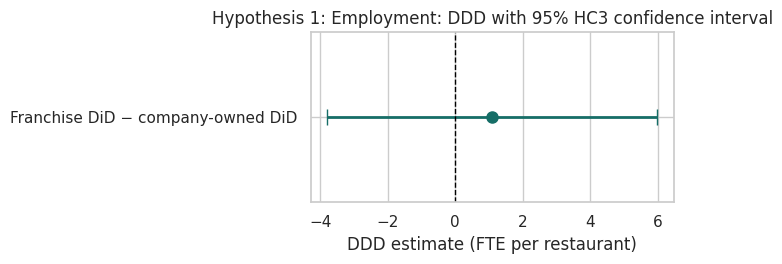

**DDD estimate:** +1.095 FTE per restaurant  
**95% HC3 CI:** [-3.797, +5.987]

### Hypothesis 2: Meal prices

**Outcome:** $\Delta MealPrice_i$ is the after-minus-before change in USD per meal basket. The meal basket is a medium soda, small fries, and an entrée.

**Regression:** $\Delta MealPrice_i = \alpha + \beta NJ_i + \gamma Franchise_i + \delta(NJ_i \times Franchise_i) + \varepsilon_i$

**Hypothesis test:** The coefficient of interest is $\delta$, the interaction between New Jersey and franchise status. It measures the franchise DiD minus the company-owned DiD.

GT(_tbl_data=  __index_level_0__       __index_level_1__                    0
0              coef                  NJ (β)  0.184* <br> (0.079)
1              coef           Franchise (γ)   0.113 <br> (0.084)
2              coef  NJ (β) × Franchise (γ)  -0.132 <br> (0.095)
3              coef           Intercept (α)  -0.103 <br> (0.072)
4             stats            Observations                  355
5             stats                      R²                0.017, _body=<great_tables._gt_data.Body object at 0x7a68390fc320>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x7a68395aaf30>, _spanners=Spanners([SpannerInfo(spanner_id='change', spanner_level=1, spanner_label=Html(text='change'), spanner_units=None, spanner_pattern=None, vars=['0'], built=None)]), _heading=Heading(title='Hypothesis 2: Meal prices', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7a68390ce5d0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7a683998b4a0>, _source_notes=[Html(text='HC3 standard errors in parentheses')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x7a683c5ea6c0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x7a6838ff73b0>, <great_tables._gt_data.FormatInfo object at 0x7a6838fd6330>, <great_tables._gt_data.FormatInfo object at 0x7a68395c25d0>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='hidden'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=Fa

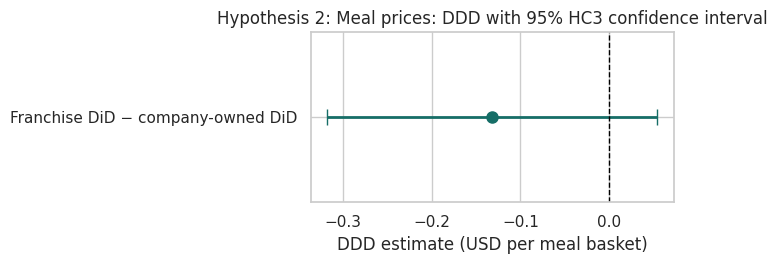

**DDD estimate:** -0.132 USD per meal basket  
**95% HC3 CI:** [-0.318, +0.055]

### Hypothesis 3: Opening hours

**Outcome:** $\Delta Hours_i$ is the after-minus-before change in hours per day. Daily weekday opening hours per restaurant.

**Regression:** $\Delta Hours_i = \alpha + \beta NJ_i + \gamma Franchise_i + \delta(NJ_i \times Franchise_i) + \varepsilon_i$

**Hypothesis test:** The coefficient of interest is $\delta$, the interaction between New Jersey and franchise status. It measures the franchise DiD minus the company-owned DiD.

GT(_tbl_data=  __index_level_0__       __index_level_1__                    0
0              coef                  NJ (β)  -0.161 <br> (0.206)
1              coef           Franchise (γ)   0.142 <br> (0.183)
2              coef  NJ (β) × Franchise (γ)   0.076 <br> (0.237)
3              coef           Intercept (α)   0.018 <br> (0.150)
4             stats            Observations                  398
5             stats                      R²                0.011, _body=<great_tables._gt_data.Body object at 0x7a68390c11d0>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x7a68390c7890>, _spanners=Spanners([SpannerInfo(spanner_id='change', spanner_level=1, spanner_label=Html(text='change'), spanner_units=None, spanner_pattern=None, vars=['0'], built=None)]), _heading=Heading(title='Hypothesis 3: Opening hours', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7a6838fa3450>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7a6838fa1e50>, _source_notes=[Html(text='HC3 standard errors in parentheses')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x7a683d1fd130>, _formats=[<great_tables._gt_data.FormatInfo object at 0x7a68390c5f10>, <great_tables._gt_data.FormatInfo object at 0x7a68390c5670>, <great_tables._gt_data.FormatInfo object at 0x7a68390c5af0>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='hidden'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=

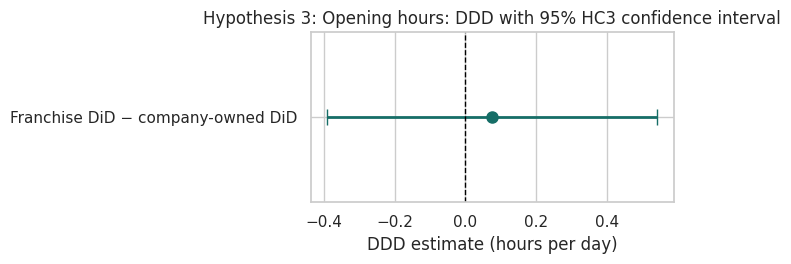

**DDD estimate:** +0.076 hours per day  
**95% HC3 CI:** [-0.391, +0.542]

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pyfixest as pf
from IPython.display import display, Markdown


# Shared regression description and variable coding
display(Markdown(
    "## Regression setup\n\n"
    "Each regression uses restaurants observed in both survey waves "
    "The dependent variable is the restaurant-level change: after minus before\n\n"
    r"$\Delta Y_i = \alpha + \beta NJ_i + \gamma Franchise_i "
    r"+ \delta(NJ_i \times Franchise_i) + \varepsilon_i$"
    "\n\n"
    "- $NJ_i=1$ for New Jersey and $0$ for Pennsylvania\n"
    "- $Franchise_i=1$ for franchise and $0$ for company-owned restaurants\n"
    "- $\\alpha$: mean change for Pennsylvania company-owned restaurants "
    "(the reference group)\n"
    "- $\\beta$: company-owned DiD (New Jersey change minus Pennsylvania change)\n"
    "- $\\gamma$: franchise-minus-company-owned difference in Pennsylvania changes\n"
    "- $\\delta$: franchise DiD minus company-owned DiD (the DDD)\n"
    "- $\\varepsilon_i$: the part of the restaurant's change not explained by the model\n\n"
    "For each outcome, we test $H_0: \\delta=0$ against "
    "$H_A: \\delta\\neq0$"
))


# One specification for each outcome
hypothesis_specs = [
    (
        "employment",
        "Hypothesis 1: Employment",
        "FTE",
        "FTE per restaurant",
        "FTE = full-time employees + managers + 0.5 × part-time employees.",
    ),
    (
        "meal_price",
        "Hypothesis 2: Meal prices",
        "MealPrice",
        "USD per meal basket",
        "The meal basket is a medium soda, small fries, and an entrée.",
    ),
    (
        "hours",
        "Hypothesis 3: Opening hours",
        "Hours",
        "hours per day",
        "Daily weekday opening hours per restaurant.",
    ),
]

outcome_labels = {
    "employment": "Employment (FTE)",
    "meal_price": "Meal basket price (USD)",
    "hours": "Daily opening hours",
}

for outcome, title, symbol, unit, definition in hypothesis_specs:

    # Description of the dependent variable and the test for this hypothesis
    display(Markdown(
        f"### {title}\n\n"
        f"**Outcome:** $\\Delta {symbol}_i$ is the after-minus-before change "
        f"in {unit}. {definition}\n\n"
        f"**Regression:** $\\Delta {symbol}_i = \\alpha + \\beta NJ_i + "
        f"\\gamma Franchise_i + \\delta(NJ_i \\times Franchise_i) + "
        f"\\varepsilon_i$\n\n"
        "**Hypothesis test:** The coefficient of interest is "
        "$\\delta$, the interaction between New Jersey and franchise status. "
        "It measures the franchise DiD minus the company-owned DiD."
    ))

    # Using the outcome-specific paired sample prepared earlier
    sample = samples[outcome].copy()

    # Code franchise = 1 and company-owned = 0
    sample["franchise"] = sample["ownership"].eq("Franchise").astype(int)

    # Estimating the regression once, using HC3 standard errors
    model = pf.feols(
        "change ~ state * franchise",
        data=sample,
        vcov="HC3",
    )


    # Displaying the regression table for this hypothesis
    display(pf.etable(
        model,
        type="gt",
        labels={
            "Intercept": "Intercept (α)",
            "state": "NJ (β)",
            "franchise": "Franchise (γ)",
            "state:franchise": "NJ × Franchise (δ; DDD)",
        },
        caption=title,
        notes="HC3 standard errors in parentheses",
    ))

    # Get the DDD estimate and its 95% confidence interval
    # directly from the same fitted regression
    ddd_estimate = model.coef().loc["state:franchise"]
    ddd_ci = model.confint().loc["state:franchise"].to_numpy()
    ci_lower, ci_upper = ddd_ci

    # Save the DDD result from this same fitted model for the later
    # robustness-check table. This does not refit or change the model.
    main_ddd_rows.append({
        "Outcome": outcome_labels[outcome],
        "Effect": "Franchise minus company-owned (DDD)",
        "Estimate": ddd_estimate,
        "HC3 SE": model.se().loc["state:franchise"],
        "CI lower": ci_lower,
        "CI upper": ci_upper,
        "p-value": model.pvalue().loc["state:franchise"],
        "Restaurants": len(model.resid()),
    })

    # Plot only the coefficient tested by the hypothesis:
    # franchise DiD minus company-owned DiD
    figure, axis = plt.subplots(figsize=(7, 2.8))

    axis.errorbar(
        x=[ddd_estimate],
        y=[0],
        xerr=np.array([[
            ddd_estimate - ci_lower
        ], [
            ci_upper - ddd_estimate
        ]]),
        fmt="o",
        color="#166e67",
        capsize=6,
        markersize=8,
        linewidth=2,
    )

    # The vertical zero line marks the null hypothesis: δ = 0
    axis.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
    )

    axis.set_yticks(
        [0],
        ["Franchise DiD − company-owned DiD"],
    )
    axis.set_ylim(-0.7, 0.7)
    axis.set_xlabel(f"DDD estimate ({unit})")
    axis.set_title(f"{title}: DDD with 95% HC3 confidence interval")

    figure.tight_layout()
    plt.show()
    display(Markdown(
        f"**DDD estimate:** {ddd_estimate:+.3f} {unit}  \n"
        f"**95% HC3 CI:** [{ci_lower:+.3f}, {ci_upper:+.3f}]"
    ))

results = pd.DataFrame(main_ddd_rows)

## 3.2 Robustness Checks

1. **Chain-adjusted changes:** add chain indicators to the first-difference regression. These allow common chain-specific time shocks, not chain-specific treatment effects. They do not resolve missing ownership-by-state cells within a chain.
2. **Employment without permanent closures:** exclude permanently closed restaurants to show how the extensive margin affects the estimate. This changes the estimand and is not a correction for non-random survival.
3. **Opening hours including permanent closures:** assign zero follow-up hours to permanent closures only. Temporary closures, refusals, and other missing hours remain missing.
4. **Log meal-price changes:** estimate 100 times the change in log basket prices for strictly positive paired prices. Units are log points, approximately percentage points for small changes, rather than dollars.

The table reports only the franchise-minus-company DDD for each specification. Different samples, units, and assumptions mean these rows should not be pooled into one estimate.

In [ ]:
outcome_labels = {
    "employment": "Employment (FTE)",
    "meal_price": "Meal basket price (USD)",
    "hours": "Daily opening hours",
}


# Explaining the four robustness checks
display(Markdown(
    "## Robustness Checks\n\n"
    "1. **Chain-adjusted changes:** Add chain indicators to the first-difference "
    "regression. These account for average chain-specific changes, not chain-specific "
    "treatment effects.\n"
    "2. **Employment excluding permanent closures:** Remove permanently closed "
    "restaurants. This changes the sample and does not correct for non-random survival.\n"
    "3. **Opening hours including permanent closures:** Assign zero follow-up hours "
    "to permanently closed restaurants; other missing follow-up hours remain missing.\n"
    "4. **Log meal prices:** Use 100 times the change in log prices for restaurants "
    "with positive prices in both waves. The units are log points, approximately "
    "percentage points for small changes.\n\n"
    "The table reports the franchise-minus-company-owned DDD for each specification. "
    "The rows use different samples, units, or assumptions and should not be pooled."
))


# Fitting one model and collect its DDD estimate and HC3 uncertainty
def fit_and_record_ddd(sample, outcome_label, specification, chain_adjusted=False):
    sample = sample.copy()

    # Code franchise = 1 and company-owned = 0
    sample["franchise"] = sample["ownership"].eq("Franchise").astype(int)

    # Adding chain indicators for the chain-adjusted specification
    formula = "change ~ state * franchise"
    if chain_adjusted:
        formula += " + C(chain)"

    # Estimating the regression with HC3 standard errors
    model = pf.feols(
        formula,
        data=sample,
        vcov="HC3",
    )

    # The interaction coefficient is the DDD: franchise DiD minus company-owned DiD
    ddd_name = "state:franchise"
    estimate = model.coef().loc[ddd_name]
    standard_error = model.se().loc[ddd_name]
    ci_lower, ci_upper = model.confint().loc[ddd_name].to_numpy()
    p_value = model.pvalue().loc[ddd_name]

    return {
        "Outcome": outcome_label,
        "Specification": specification,
        "Estimate": estimate,
        "HC3 SE": standard_error,
        "CI lower": ci_lower,
        "CI upper": ci_upper,
        "p-value": p_value,
        "Restaurants": len(model.resid()),
    }


# Starting with the main DDD results calculated earlier
main_ddd = results.loc[
    results["Effect"].eq("Franchise minus company-owned (DDD)")
].copy()

# Using a consistent standard-error column name
if "HC3 SE" not in main_ddd.columns:
    if "Robust SE" in main_ddd.columns:
        main_ddd = main_ddd.rename(columns={"Robust SE": "HC3 SE"})
    else:
        raise KeyError(
            "The main results need an 'HC3 SE' or 'Robust SE' column."
        )

main_ddd["Specification"] = "Main specification"
sensitivity_rows = main_ddd.to_dict("records")


# 1. Chain-adjusted DDD estimates for all three outcomes
for outcome, label in outcome_labels.items():
    sensitivity_rows.append(
        fit_and_record_ddd(
            sample=samples[outcome],
            outcome_label=label,
            specification="Chain-adjusted changes",
            chain_adjusted=True,
        )
    )


# 2. Employment analysis excluding restaurants permanently closed by Wave 2
employment_survivors = samples["employment"].loc[
    samples["employment"]["status2"].ne(3)
].copy()

sensitivity_rows.append(
    fit_and_record_ddd(
        sample=employment_survivors,
        outcome_label=outcome_labels["employment"],
        specification="Exclude permanent closures",
    )
)


# 3. Opening-hours analysis assigning zero follow-up hours to permanent closures
hours_with_closures = analysis.copy()

hours_with_closures.loc[
    hours_with_closures["status2"].eq(3),
    "hours_after",
] = 0.0

hours_with_closures = hours_with_closures.dropna(
    subset=["hours_before", "hours_after"]
).copy()

hours_with_closures["change"] = (
    hours_with_closures["hours_after"]
    - hours_with_closures["hours_before"]
)

sensitivity_rows.append(
    fit_and_record_ddd(
        sample=hours_with_closures,
        outcome_label=outcome_labels["hours"],
        specification="Permanent closures assigned zero hours",
    )
)


# 4. Meal-price analysis using 100 times the log-price change
log_prices = samples["meal_price"].loc[
    samples["meal_price"][
        ["meal_price_before", "meal_price_after"]
    ].gt(0).all(axis=1)
].copy()

log_prices["change"] = 100 * (
    np.log(log_prices["meal_price_after"])
    - np.log(log_prices["meal_price_before"])
)

sensitivity_rows.append(
    fit_and_record_ddd(
        sample=log_prices,
        outcome_label="Meal basket price (100 log points)",
        specification="Positive paired prices; log change",
    )
)


# Displaying the main estimates alongside the sensitivity checks
sensitivity_results = pd.DataFrame(sensitivity_rows)

display(
    sensitivity_results[
        [
            "Outcome",
            "Specification",
            "Estimate",
            "HC3 SE",
            "CI lower",
            "CI upper",
            "p-value",
            "Restaurants",
        ]
    ].round(4)
)

## Robustness Checks

1. **Chain-adjusted changes:** Add chain indicators to the first-difference regression. These account for average chain-specific changes, not chain-specific treatment effects.
2. **Employment excluding permanent closures:** Remove permanently closed restaurants. This changes the sample and does not correct for non-random survival.
3. **Opening hours including permanent closures:** Assign zero follow-up hours to permanently closed restaurants; other missing follow-up hours remain missing.
4. **Log meal prices:** Use 100 times the change in log prices for restaurants with positive prices in both waves. The units are log points, approximately percentage points for small changes.

The table reports the franchise-minus-company-owned DDD for each specification. The rows use different samples, units, or assumptions and should not be pooled.

,Outcome,Specification,Estimate,HC3 SE,CI lower,CI upper,p-value,Restaurants
0,Employment (FTE),Main specification,1.0953,2.4879,-3.7966,5.9871,0.6600,384
1,Meal basket price (USD),Main specification,-0.1318,0.0948,-0.3181,0.0546,0.1653,355
2,Daily opening hours,Main specification,0.0757,0.2372,-0.3907,0.5420,0.7499,398
3,Employment (FTE),Chain-adjusted changes,1.1417,2.4422,-3.6603,5.9436,0.6404,384
4,Meal basket price (USD),Chain-adjusted changes,-0.2084,0.1010,-0.4069,-0.0098,0.0398,355
5,Daily opening hours,Chain-adjusted changes,0.0674,0.2134,-0.3521,0.4869,0.7523,398
6,Employment (FTE),Exclude permanent closures,0.5422,2.4910,-4.3558,5.4403,0.8278,378
7,Daily opening hours,Permanent closures assigned zero hours,0.5581,0.4256,-0.2785,1.3948,0.1904,404
8,Meal basket price (100 log points),Positive paired prices; log change,-4.4612,2.8657,-10.0973,1.1749,0.1204,355


## Interpretation of the Robustness Checks

- **Employment:** The DDD estimates are positive but imprecise across the main, chain adjusted, and survivor-only specifications. All confidence intervals include zero. We find no clear evidence that the employment response differed by ownership.

- **Meal prices:** The DDD is negative in all three specifications, meaning the estimated NJ–PA price change is lower for franchises than for company-owned restaurants. Only the chain-adjusted estimate excludes zero (−$0.208 per basket; 95% CI: −$0.404 to −$0.013; p = 0.037). The main and log-price estimates are not statistically significant. The price result is therefore specification-sensitive and should be treated as exploratory, not as robust evidence of a causal difference.

- **Opening hours:** The estimated DDD is positive in both specifications, but both confidence intervals include zero. Assigning zero follow-up hours to permanent closures increases the point estimate, but neither specification provides clear evidence of an ownership difference.

## Reference

Card, D., and Krueger, A. B. (1994). *Minimum Wages and Employment: A Case Study of the Fast-Food Industry in New Jersey and Pennsylvania.* American Economic Review, 84(4), 772-793.
